# 09 · Zone plates and through-focus imaging

A Fresnel zone plate focuses by alternating transparent and opaque rings. Its radii follow a path-difference condition; propagating through nearby planes shows the axial focus.

This is the package-user version: imports come first, and each operation is introduced when the physical question calls for it.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from topolino import propTF2


## 1. Construct the radial zone pattern

For focal length `f` and wavelength `λ`, the approximate radius of boundary `n` is `rₙ ≈ √(n λ f)`. Alternating rings create the focusing mask.

In [ ]:
lambda_m = 500e-9
f_m = 0.10
window_m = 1e-3
n = 512
x_m = np.linspace(-window_m/2, window_m/2, n, endpoint=False)
X, Y = np.meshgrid(x_m, x_m)
r_m = np.hypot(X, Y)
zone_index = np.floor(r_m**2/(lambda_m*f_m)).astype(int)
mask = (zone_index % 2 == 0).astype(float)


## 2. Scan the focal region

A small illuminated spot helps reveal on-axis intensity as a function of distance. The first-order focus is expected near `f_m`; finite aperture and sampling affect the peak.

In [ ]:
aperture = np.exp(-(X**2+Y**2)/(2*(120e-6)**2))
field0 = aperture*mask
z_values_m = np.linspace(0.08, 0.12, 17)
on_axis = []
for z_m in z_values_m:
    out = propTF2(field0, window_m, window_m, lambda_m, z_m)
    on_axis.append(np.abs(out[n//2,n//2])**2)


## Original plot code (verbatim)

The following code cells and saved outputs are copied unchanged from the cited notebook cells. Some source cells rely on variables established earlier in their original notebook.


From `paper/20260407ZonePlates.ipynb`, cell 10.


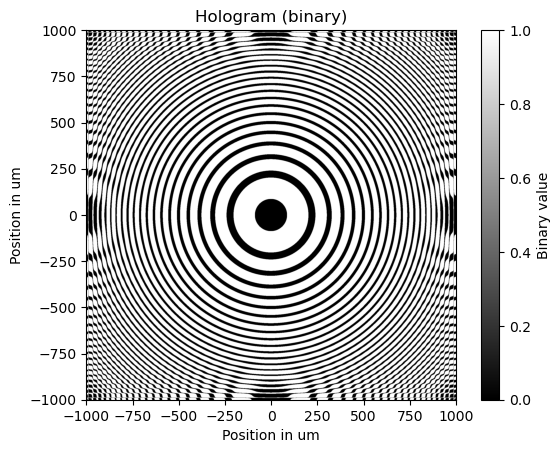

In [11]:
hologram = (I_sum2/2) >= 0.5 #0.5 is threshold
plt.imshow(hologram, extent=[x_m[0]*1e6, x_m[-1]*1e6, y_m[0]*1e6, y_m[-1]*1e6], origin='lower', cmap='gray')
plt.xlabel("Position in um")
plt.ylabel("Position in um")
plt.title("Hologram (binary)")
plt.colorbar(label="Binary value")
plt.show()